<a href="https://colab.research.google.com/github/farielfahriza/bank-telemarketing-analysis/blob/main/bank_telemarketing_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telemarketing Campaign Analysis: Who to Call, When, and How Often

**Author:** M Fariel Fahriza Tielung
**Tools:** Python (pandas, NumPy, matplotlib, seaborn), Google Colab
**Dataset:** [Bank Marketing – UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing)

---

## Background

A Portuguese bank ran direct marketing campaigns by phone to offer customers a term deposit. Phone campaigns are costly: every call takes agent time, yet most calls do not result in a subscription.

This project analyzes 45,211 customer contacts (May 2008 – November 2010) to understand which customers are most likely to subscribe and how the bank can target its calls more efficiently.

## Business Questions

1. What is the overall conversion rate of the campaign?
2. Which customer profiles (age, job, balance) are most likely to convert?
3. Do contact channel and timing affect conversion?
4. At what point do additional follow-up calls stop being worth the effort?
5. Are customers who converted in a previous campaign more likely to convert again?
6. How should the bank target its next campaign?

## Contents

1. Data Loading
2. Data Overview
3. Data Cleaning
4. Feature Engineering
5. Customer Profile Analysis
6. Channel, Timing & Previous Campaign Analysis
7. Impact of a Follow-up Cap
8. Key Insights & Recommendations

## 1. Data Loading
The dataset is loaded directly from the UCI repository using the `ucimlrepo` package.

In [1]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd

bank = fetch_ucirepo(id=222)
df = pd.concat([bank.data.features, bank.data.targets], axis=1)

print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


## 2. Data Overview
Checking structure, data types, missing values, and the distribution of the target variable (`y`: whether the customer subscribed).

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [3]:
df.describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [4]:
df.isna().sum()

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


In [5]:
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True) * 100)

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [6]:
for col in ['job', 'marital', 'education', 'contact', 'poutcome']:
    print(df[col].value_counts(dropna=False), '\n')

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
NaN               288
Name: count, dtype: int64 

marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64 

education
secondary    23202
tertiary     13301
primary       6851
NaN           1857
Name: count, dtype: int64 

contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64 

poutcome
NaN        36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64 



**Observations:**
- Overall conversion rate is **11.7%** (5,289 of 45,211 customers).
- `poutcome` has 36,959 missing values. These are customers who were never contacted in a previous campaign (`pdays = -1`), not truly missing data.
- `contact` has 13,020 missing values (contact channel not recorded).
- `day_of_week` actually contains the day of the month (1–31), so it will be renamed.
- `balance` contains negative values (overdrafts), which are valid.
- `campaign` (max 63) and `previous` (max 275) contain extreme values. They are kept and grouped rather than removed.
- `duration` is only known after a call ends, so it will **not** be used to inform targeting decisions.

## 3. Data Cleaning
- Renamed `day_of_week` to `day`.
- Created `converted` (1 = subscribed, 0 = not) so conversion rate can be calculated as a mean.
- Filled missing `job`, `education`, and `contact` with `"unknown"` instead of dropping rows, to avoid losing ~30% of the data and to allow analysis of unrecorded cases.
- Labeled `poutcome` as `"not_contacted"` for customers with `pdays = -1`.
- Added `previously_contacted` flag.

In [7]:
# 1. Ganti nama kolom yang menyesatkan
df = df.rename(columns={'day_of_week': 'day'})

# 2. Ubah target jadi angka 0/1 (biar conversion rate gampang dihitung pakai mean)
df['converted'] = (df['y'] == 'yes').astype(int)

# 3. Isi nilai kosong di kolom kategori dengan 'unknown' (jangan dihapus, datanya terlalu banyak)
for col in ['job', 'education', 'contact']:
    df[col] = df[col].fillna('unknown')

# 4. poutcome: kosong karena belum pernah dihubungi -> 'not_contacted'
df.loc[df['pdays'] == -1, 'poutcome'] = 'not_contacted'
df['poutcome'] = df['poutcome'].fillna('unknown')

# 5. Flag: pernah dihubungi di kampanye sebelumnya atau belum
df['previously_contacted'] = (df['pdays'] != -1).astype(int)

# 6. Cek duplikat
print('Jumlah duplikat:', df.duplicated().sum())

Jumlah duplikat: 0


In [8]:
print(df.isna().sum())
print(df['poutcome'].value_counts())
print(df['converted'].mean() * 100)

age                     0
job                     0
marital                 0
education               0
default                 0
balance                 0
housing                 0
loan                    0
contact                 0
day                     0
month                   0
duration                0
campaign                0
pdays                   0
previous                0
poutcome                0
y                       0
converted               0
previously_contacted    0
dtype: int64
poutcome
not_contacted    36954
failure           4901
other             1840
success           1511
unknown              5
Name: count, dtype: int64
11.698480458295547


## 4. Feature Engineering
Grouped continuous variables into bins for easier comparison:
- `age_group`, `balance_group`, and `campaign_group` (number of calls; extreme values fall into "11+").
- Ordered `month` chronologically for plotting.

In [9]:
import numpy as np

# 1. Kelompok umur
df['age_group'] = pd.cut(df['age'],
                         bins=[17, 25, 35, 45, 55, 65, 100],
                         labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])

# 2. Kelompok saldo
df['balance_group'] = pd.cut(df['balance'],
                             bins=[-np.inf, -1, 0, 1000, 5000, np.inf],
                             labels=['Negative', 'Zero', '1-1K', '1K-5K', '5K+'])

# 3. Kelompok jumlah telepon di kampanye ini (outlier 63x masuk ke '11+')
df['campaign_group'] = pd.cut(df['campaign'],
                              bins=[0, 1, 2, 3, 5, 10, np.inf],
                              labels=['1', '2', '3', '4-5', '6-10', '11+'])

# 4. Urutkan bulan biar chart nanti nggak acak (default-nya urut abjad)
month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
df['month'] = pd.Categorical(df['month'], categories=month_order, ordered=True)

In [10]:
for col in ['age_group', 'balance_group', 'campaign_group']:
    summary = df.groupby(col, observed=True).agg(
        customers=('converted', 'count'),
        conversion_rate=('converted', 'mean')
    )
    summary['conversion_rate'] = (summary['conversion_rate'] * 100).round(2)
    print(summary, '\n')

           customers  conversion_rate
age_group                            
18-25           1336            23.95
26-35          15571            12.00
36-45          13856             9.39
46-55           9548             9.35
56-65           4149            14.12
65+              751            42.61 

               customers  conversion_rate
balance_group                            
Negative            3766             5.58
Zero                3514             8.31
1-1K               23300            10.90
1K-5K              11786            15.33
5K+                 2845            15.50 

                customers  conversion_rate
campaign_group                            
1                   17544            14.60
2                   12505            11.20
3                    5521            11.19
4-5                  5286             8.63
6-10                 3159             6.52
11+                  1196             3.93 



## 5. Customer Profile Analysis
Comparing conversion rates across age, job, and balance groups. The red dashed line in each chart shows the overall conversion rate (11.7%).

In [11]:
job_summary = df.groupby('job').agg(
    customers=('converted', 'count'),
    conversion_rate=('converted', 'mean')
).sort_values('conversion_rate', ascending=False)
job_summary['conversion_rate'] = (job_summary['conversion_rate'] * 100).round(2)
print(job_summary)

               customers  conversion_rate
job                                      
student              938            28.68
retired             2264            22.79
unemployed          1303            15.50
management          9458            13.76
admin.              5171            12.20
self-employed       1579            11.84
unknown              288            11.81
technician          7597            11.06
services            4154             8.88
housemaid           1240             8.79
entrepreneur        1487             8.27
blue-collar         9732             7.27


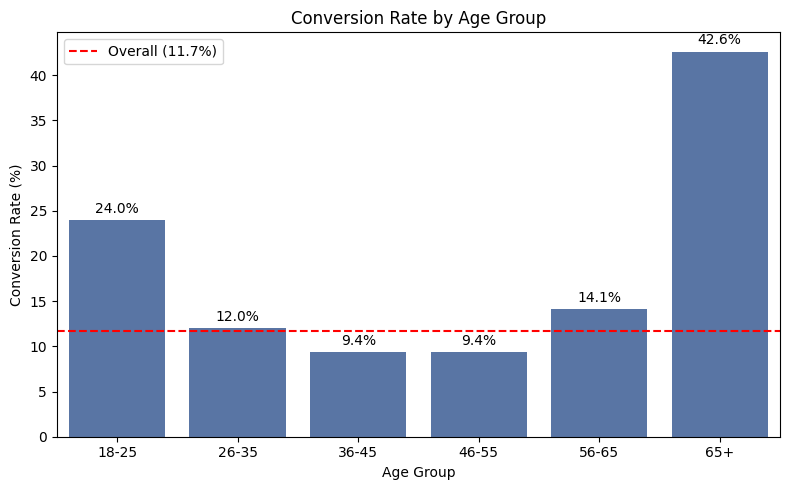

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

overall_rate = df['converted'].mean() * 100

age_rate = df.groupby('age_group', observed=True)['converted'].mean() * 100

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=age_rate.index, y=age_rate.values, color='#4C72B0')
plt.axhline(overall_rate, color='red', linestyle='--', label=f'Overall ({overall_rate:.1f}%)')

for i, v in enumerate(age_rate.values):
    ax.text(i, v + 0.8, f'{v:.1f}%', ha='center')

plt.title('Conversion Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Conversion Rate (%)')
plt.legend()
plt.tight_layout()
plt.savefig('conversion_by_age.png', dpi=150)
plt.show()

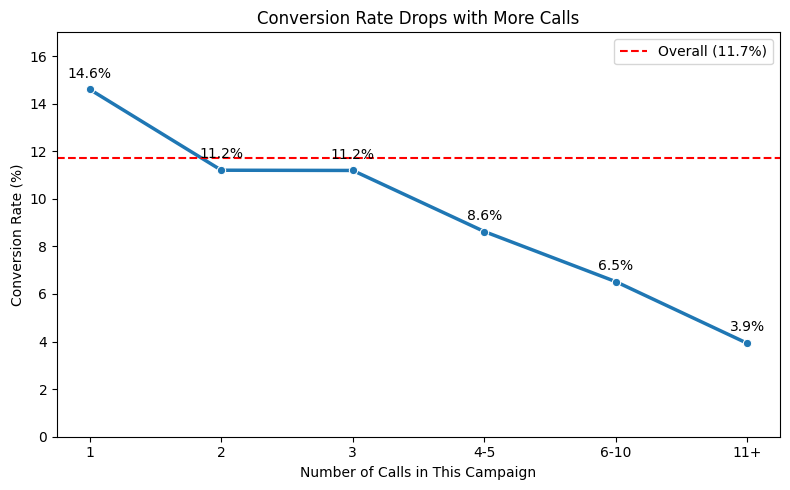

In [13]:
camp_rate = df.groupby('campaign_group', observed=True)['converted'].mean() * 100

plt.figure(figsize=(8, 5))
sns.lineplot(x=camp_rate.index.astype(str), y=camp_rate.values, marker='o', linewidth=2.5)
plt.axhline(overall_rate, color='red', linestyle='--', label=f'Overall ({overall_rate:.1f}%)')

for i, v in enumerate(camp_rate.values):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center')

plt.title('Conversion Rate Drops with More Calls')
plt.xlabel('Number of Calls in This Campaign')
plt.ylabel('Conversion Rate (%)')
plt.ylim(0, 17)
plt.legend()
plt.tight_layout()
plt.savefig('conversion_by_calls.png', dpi=150)
plt.show()

## 6. Channel, Timing & Previous Campaign Analysis

In [14]:
contact_summary = df.groupby('contact').agg(
    customers=('converted', 'count'),
    conversion_rate=('converted', 'mean')
)
contact_summary['conversion_rate'] = (contact_summary['conversion_rate'] * 100).round(2)
print(contact_summary)

           customers  conversion_rate
contact                              
cellular       29285            14.92
telephone       2906            13.42
unknown        13020             4.07


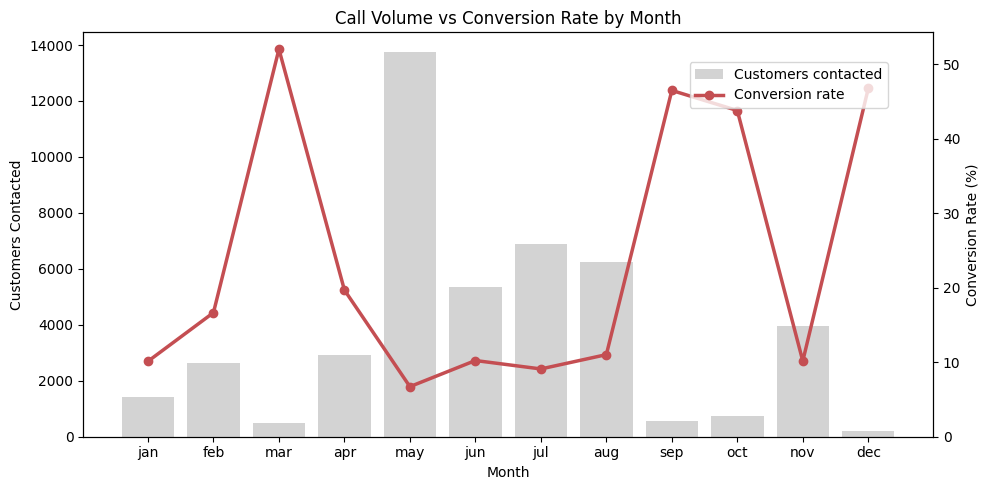

In [15]:
month_summary = df.groupby('month', observed=True).agg(
    customers=('converted', 'count'),
    conversion_rate=('converted', 'mean')
)
month_summary['conversion_rate'] *= 100

fig, ax1 = plt.subplots(figsize=(10, 5))

# Batang = jumlah nasabah yang ditelepon
ax1.bar(month_summary.index.astype(str), month_summary['customers'], color='lightgray', label='Customers contacted')
ax1.set_ylabel('Customers Contacted')
ax1.set_xlabel('Month')

# Garis = conversion rate (sumbu Y kanan)
ax2 = ax1.twinx()
ax2.plot(month_summary.index.astype(str), month_summary['conversion_rate'], color='#C44E52', marker='o', linewidth=2.5, label='Conversion rate')
ax2.set_ylabel('Conversion Rate (%)')
ax2.set_ylim(0, None)

plt.title('Call Volume vs Conversion Rate by Month')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.88))
plt.tight_layout()
plt.savefig('volume_vs_conversion_month.png', dpi=150)
plt.show()

In [16]:
pout_rate = df.groupby('poutcome')['converted'].agg(['count', 'mean'])
pout_rate['mean'] = (pout_rate['mean'] * 100).round(2)
print(pout_rate.sort_values('mean', ascending=False))

               count   mean
poutcome                   
success         1511  64.73
unknown            5  40.00
other           1840  16.68
failure         4901  12.61
not_contacted  36954   9.16


## 7. Impact of a Follow-up Cap
Estimating how many calls could be saved by limiting follow-ups to a maximum of 3 calls per customer, and how many conversions could be at risk in the worst case.

In [17]:
total_calls = df['campaign'].sum()
total_conversions = df['converted'].sum()

over3 = df[df['campaign'] > 3]
calls_saved = (over3['campaign'] - 3).sum()
conversions_at_risk = over3['converted'].sum()

print(f'Total calls: {total_calls:,}')
print(f'Calls saved with a 3-call cap: {calls_saved:,} ({calls_saved/total_calls*100:.1f}%)')
print(f'Conversions at risk (max): {conversions_at_risk:,} ({conversions_at_risk/total_conversions*100:.1f}%)')

Total calls: 124,956
Calls saved with a 3-call cap: 36,916 (29.5%)
Conversions at risk (max): 709 (13.4%)


In [18]:
pd.crosstab(df['month'], df['contact'])

contact,cellular,telephone,unknown
month,,,
jan,1265,129,9
feb,2362,274,13
mar,417,53,7
apr,2727,199,6
may,5331,460,7975
jun,729,80,4532
jul,5767,852,276
aug,5950,246,51
sep,466,66,47


## Key Insights

1. **Low overall conversion.** Only 11.7% of 45,211 contacted customers subscribed to a term deposit, meaning roughly 9 out of 10 calls did not convert.

2. **Students and retirees convert best.** Conversion is highest among students (28.7%) and retirees (22.8%), and customers aged 65+ reach 42.6%. Blue-collar workers, the largest group contacted (9,732), convert the least (7.3%).

3. **Higher balance, higher conversion.** Customers with balances above 1K convert at ~15%, while those with negative balances convert at only 5.6%.

4. **Past success is the strongest signal.** Customers who subscribed in a previous campaign converted at 64.7%, about 7x higher than customers never contacted before (9.2%).

5. **More calls, diminishing returns.** Conversion drops from 14.6% on the first call to 3.9% after 11+ calls.

6. **Volume does not equal results.** May had the highest call volume (~30% of all calls) but the lowest conversion rate, while low-volume months (Mar, Sep, Oct, Dec) converted at 45–50%.

7. **Channel matters less than targeting.** Cellular (14.9%) and telephone (13.4%) perform similarly; calls with unrecorded contact type convert at only 4.1%.

## Recommendations

1. **Call warm leads first.** Prioritize customers with a successful previous campaign outcome.
2. **Prioritize high-propensity segments.** Students, retirees, customers aged 60+, and customers with higher balances, while keeping the high-volume 26–35 group in the pipeline.
3. **Cap follow-ups at 3 calls.** This would free up 29.5% of total call volume (36,916 calls) while putting at most 13.4% of conversions at risk.
4. **Avoid untargeted mass-calling periods.** Spread campaigns across the year and focus on selected customers rather than calling everyone at once.
5. **Improve data recording.** Ensure contact channel is always captured so campaign performance can be measured accurately.

## Limitations

- Call `duration` was excluded from targeting analysis since it is only known after a call ends.
- Findings show correlation, not causation (e.g., repeated calls may reflect low-interest customers rather than cause lower conversion).
- High conversion in low-volume months may reflect selective targeting rather than seasonality.